# Essential Food Price Movement Prediction
Machine Learning and Pattern Recognition

**Student:** Nivethan R.  
**Student ID:** 224138H

This project compares bagging, boosting and stacking on Sri Lankan retail-price movements. The question is whether they can beat using the previous reported price as the next prediction.

**Source:** Department of Census and Statistics (DCS), [weekly retail prices for Colombo district](https://www.statistics.gov.lk/InflationAndPrices/StaticalInformation/RetailPrices). Original PDFs, checksums and extraction records are included under `data/`. See `SOURCES.md`.

**AI acknowledgement:** OpenAI Codex assisted with code and draft explanations. See `AI_USAGE.md` for the contribution acknowledgement.

## Data and features
The dataset contains 20 food series in LKR/kg from the current-week column of official DCS reports. Files are downloaded by `scripts/download_dcs.py` and parsed by `scripts/prepare_dcs.py`.

Only current-report prices are used. The PDF's earlier-year averages, ranges and percentage-change columns are excluded. Missing releases stay missing; there is no interpolation.

DCS lists four reporting periods per month. `slot` is a continuous reporting-period index, not an ISO week. Dates encode W1, W2, W3 and W4 as days 1, 8, 15 and 22 for plotting; they are not exact collection dates.

Features use prices 1, 2, 4 and 8 reports earlier, past four-report mean and standard deviation, previous movement, four-period trend, seasonality and food identity. The target is fractional price movement. The model's predicted movement is converted back to LKR/kg.

In [1]:
from pathlib import Path
import hashlib
import json
import time
import joblib
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from xgboost import XGBRegressor

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data/processed/dcs_weekly_prices.csv").exists())
ARTIFACTS = ROOT / 'backend/artifacts'
DATA = ROOT / 'data/processed/dcs_weekly_prices.csv'
SOURCE_URL = 'https://www.statistics.gov.lk/InflationAndPrices/StaticalInformation/RetailPrices'
NUMERIC = ['lag_1', 'lag_2', 'lag_4', 'lag_8', 'mean_4', 'std_4', 'change_1', 'trend_4', 'season_sin', 'season_cos']
FEATURES = NUMERIC + ['commodity']
LABELS = {'bagging': 'Random forest', 'boosting': 'XGBoost', 'stacking': 'Temporal stacking', 'baseline': 'Previous report'}
MODEL_KEYS = ['bagging', 'boosting', 'stacking']
CUTOFF = '2026-01-01'


def slot_date(slot):
    year, remainder = divmod(int(slot), 48)
    month, week = divmod(remainder, 4)
    return pd.Timestamp(year=year, month=month + 1, day=1 + week * 7)


def period_label(slot):
    date = slot_date(slot)
    return f'{date:%Y-%m}-W{(date.day - 1) // 7 + 1}'


def load_panel():
    return pd.read_csv(DATA, parse_dates=['date']).sort_values(['slot', 'commodity']).reset_index(drop=True)


def make_features(panel, require_target=True):
    pieces = []
    for food, group in panel.groupby('commodity'):
        g = group.set_index('slot').reindex(range(int(group.slot.min()), int(group.slot.max()) + 1))
        g.index.name = 'slot'
        g['commodity'] = food
        g['date'] = [slot_date(s) for s in g.index]
        g['market'] = 'Colombo district'
        for lag in [1, 2, 4, 8]:
            g[f'lag_{lag}'] = g.price.shift(lag)
        past = g.price.shift(1)
        g['mean_4'] = past.rolling(4).mean()
        g['std_4'] = past.rolling(4).std()
        g['change_1'] = g.lag_1 / g.lag_2 - 1
        g['trend_4'] = g.lag_1 / g.lag_4 - 1
        season = (g.index % 48) / 48
        g['season_sin'], g['season_cos'] = np.sin(2 * np.pi * season), np.cos(2 * np.pi * season)
        g['target'] = g.price / g.lag_1 - 1
        pieces.append(g.reset_index())
    required = FEATURES + (['price', 'target'] if require_target else [])
    return pd.concat(pieces, ignore_index=True).dropna(subset=required).sort_values(['slot', 'commodity']).reset_index(drop=True)




In [2]:
panel = load_panel()
rows = make_features(panel)
train = rows.loc[rows.date < CUTOFF].copy()
test = rows.loc[rows.date >= CUTOFF].copy()
assert train.slot.max() < test.slot.min()
display(pd.DataFrame({'stage': ['Extracted prices', 'Complete feature rows', 'Training before 2026', '2026 holdout'], 'rows': [len(panel), len(rows), len(train), len(test)]}))
display(panel.groupby('commodity').agg(observations=('price','size'), first_period=('period','min'), last_period=('period','max')))
print('Training:', period_label(train.slot.min()), 'to', period_label(train.slot.max()))
print('Holdout:', period_label(test.slot.min()), 'to', period_label(test.slot.max()))

,stage,rows
0,Extracted prices,6495
1,Complete feature rows,5851
2,Training before 2026,5031
3,2026 holdout,820


,observations,first_period,last_period
commodity,,,
Brinjal,325,2019-12-W4,2026-11-W1
Cabbage,325,2019-12-W4,2026-11-W1
Carrots,325,2019-12-W4,2026-11-W1
Garlic,324,2019-12-W4,2026-11-W1
Green beans,325,2019-12-W4,2026-11-W1
Green chillies,325,2019-12-W4,2026-11-W1
Imported big onions,323,2019-12-W4,2026-11-W1
Imported potatoes,325,2019-12-W4,2026-11-W1
Leeks,325,2019-12-W4,2026-11-W1


Training: 2020-02-W4 to 2025-12-W4
Holdout: 2026-01-W1 to 2026-11-W1


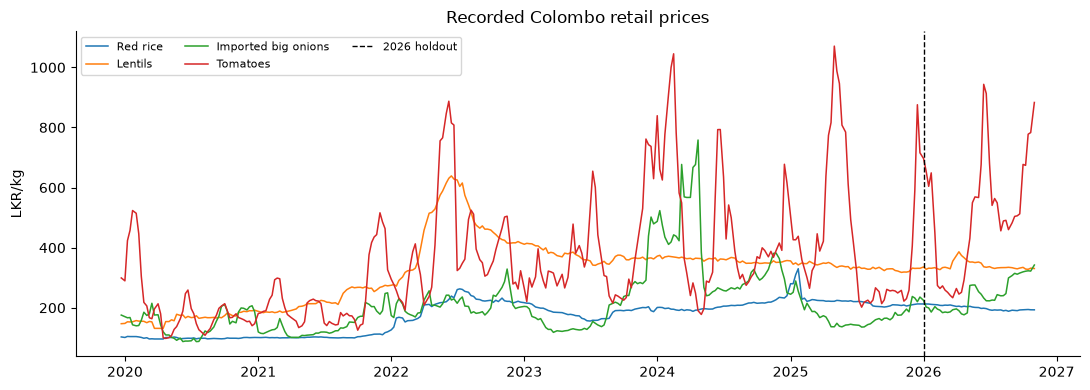

In [3]:
import matplotlib.pyplot as plt
palette = {'actual':'#242426', 'bagging':'#219575', 'boosting':'#007aff', 'stacking':'#9565cf', 'baseline':'#a4a4ad'}
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False, 'axes.spines.right': False})
for food in ['Red rice', 'Lentils', 'Imported big onions', 'Tomatoes']:
    group = panel.loc[panel.commodity == food]
    plt.plot(group.date, group.price, label=food, linewidth=1.1)
plt.axvline(pd.Timestamp(CUTOFF), color='black', linestyle='--', linewidth=1, label='2026 holdout')
plt.title('Recorded Colombo retail prices')
plt.ylabel('LKR/kg')
plt.legend(ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

## Models
**Bagging:** random forest with 120 bootstrap trees, random feature subsets, depth 9 and at least 5 rows per leaf. Averaging reduces variance, but it can smooth sharp price changes.

**Boosting:** XGBoost with 140 depth-3 trees, learning rate 0.035, subsampling 0.85 and L2 regularization 8. Trees improve the current ensemble sequentially; depth, shrinkage and regularization control complexity.

**Stacking:** random forest, XGBoost and ridge are base learners. A ridge combiner learns from predictions on three chronological validation blocks. Each block is predicted by models fitted on earlier periods only. Base models are then refitted on the full training portion.

All foods in one reporting period stay together. Scaling and one-hot encoding are fitted within each training fold. Fixed settings and seed 42 are used; no 2026 outcomes tune the settings.

References: [scikit-learn ensembles](https://scikit-learn.org/stable/modules/ensemble.html), [XGBoost API](https://xgboost.readthedocs.io/en/stable/python/python_api.html).

In [4]:
def estimator(kind):
    prep = ColumnTransformer([
        ('numeric', StandardScaler(), NUMERIC),
        ('food', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['commodity'])
    ])
    if kind == 'bagging':
        model = RandomForestRegressor(n_estimators=120, max_depth=9, min_samples_leaf=5,
                                      max_features=0.8, bootstrap=True, random_state=42, n_jobs=2)
    elif kind == 'boosting':
        model = XGBRegressor(n_estimators=140, max_depth=3, learning_rate=0.035,
                             subsample=0.85, colsample_bytree=0.85, reg_lambda=8,
                             objective='reg:squarederror', random_state=42, n_jobs=2)
    else:
        model = Ridge(alpha=20)
    return make_pipeline(prep, model)


def fit_models(train):
    slots = np.array(sorted(train.slot.unique()))
    warmup = max(16, len(slots) // 3)
    folds, oof_x, oof_y = [], [], []
    started = time.perf_counter()
    # All foods in a reporting period stay in the same fold.
    for block in np.array_split(slots[warmup:], 3):
        before, valid = train.loc[train.slot < block[0]], train.loc[train.slot.isin(block)]
        predictions = []
        for kind in ['bagging', 'boosting', 'ridge']:
            m = estimator(kind).fit(before[FEATURES], before.target)
            predictions.append(m.predict(valid[FEATURES]))
        oof_x.append(np.column_stack(predictions))
        oof_y.append(valid.target.to_numpy())
        folds.append({'train_end': period_label(before.slot.max()), 'validation_start': period_label(valid.slot.min()),
                      'validation_end': period_label(valid.slot.max()), 'rows': len(valid)})
    meta = Ridge(alpha=1).fit(np.vstack(oof_x), np.concatenate(oof_y))
    stacking_fold_seconds = time.perf_counter() - started
    models, timings = {}, {}
    for kind in ['bagging', 'boosting', 'ridge']:
        start = time.perf_counter()
        models[kind] = estimator(kind).fit(train[FEATURES], train.target)
        timings[kind] = round(time.perf_counter() - start, 3)
    timings['stacking_folds'] = round(stacking_fold_seconds, 3)
    return {'models': models, 'meta': meta}, folds, timings


def predict_returns(bundle, rows):
    values = {k: m.predict(rows[FEATURES]) for k, m in bundle['models'].items()}
    values['stacking'] = bundle['meta'].predict(np.column_stack([values[k] for k in ['bagging', 'boosting', 'ridge']]))
    return values


def predict(bundle, rows):
    changes = predict_returns(bundle, rows)
    result = rows[['date', 'slot', 'commodity', 'market', 'price', 'lag_1']].rename(columns={'price': 'actual', 'lag_1': 'previous'}).copy()
    result['period'] = [period_label(s) for s in result.slot]
    for key in MODEL_KEYS:
        result[key] = np.maximum(0.01, result.previous.to_numpy() * (1 + changes[key]))
    result['baseline'] = result.previous
    return result


def metrics(rows):
    result = []
    actual_direction = np.sign(rows.actual - rows.previous)
    for key, name in LABELS.items():
        estimate = rows[key]
        result.append({'key': key, 'name': name, 'mae': float(mean_absolute_error(rows.actual, estimate)),
                       'rmse': float(np.sqrt(mean_squared_error(rows.actual, estimate))),
                       'mape': float(np.mean(np.abs((rows.actual - estimate) / rows.actual)) * 100),
                       'r2': float(r2_score(rows.actual, estimate)) if len(rows) > 1 else None,
                       'direction_accuracy': float(np.mean(np.sign(estimate - rows.previous) == actual_direction) * 100),
                       'bias': float(np.mean(estimate - rows.actual)), 'n': len(rows)})
    return result


def forecast(bundle, panel, food, steps):
    if not 1 <= steps <= 12:
        raise ValueError('Choose between 1 and 12 reporting steps.')
    history = panel.loc[panel.commodity == food, ['slot', 'commodity', 'price']].sort_values('slot').copy()
    if history.empty:
        raise ValueError('Unknown food.')
    origin = int(history.slot.max())
    histories = {key: history.copy() for key in MODEL_KEYS}
    predictions = []
    for step in range(1, steps + 1):
        slot = origin + step
        result = {'date': str(slot_date(slot).date()), 'period': period_label(slot), 'step': step,
                  'actual': None, 'baseline': float(history.price.iloc[-1])}
        for key in MODEL_KEYS:
            next_row = pd.DataFrame([{'slot': slot, 'commodity': food, 'price': np.nan}])
            expanded = pd.concat([histories[key], next_row], ignore_index=True)
            features = make_features(expanded, require_target=False)
            features = features.loc[features.slot == slot]
            if features.empty:
                raise ValueError('The latest reporting periods do not have the required lag history.')
            change = predict_returns(bundle, features)[key][0]
            price = max(0.01, float(features.lag_1.iloc[0] * (1 + change)))
            result[key] = price
            expanded.loc[expanded.slot == slot, 'price'] = price
            histories[key] = expanded
        predictions.append(result)
    recorded = history.tail(16)
    return {'commodity': food, 'origin': period_label(origin), 'origin_date': str(slot_date(origin).date()),
            'origin_price': float(history.price.iloc[-1]), 'rows': predictions,
            'history': [{'date': str(slot_date(r.slot).date()), 'period': period_label(r.slot), 'actual': r.price} for r in recorded.itertuples()],
            'warning': 'Recursive estimates from the latest available report. Earlier missing releases are also estimated; errors can grow with each step. Actual future prices and accuracy are unknown.'}


def feature_factors(bundle, test):
    factors = {}
    sample = test.sample(min(400, len(test)), random_state=42)
    for key in ['bagging', 'boosting']:
        importance = permutation_importance(bundle['models'][key], sample[FEATURES], sample.target,
                                            scoring='neg_mean_absolute_error', n_repeats=3, random_state=42)
        factors[key] = sorted([{'feature': feature, 'increase_in_return_mae': float(value)}
                               for feature, value in zip(FEATURES, importance.importances_mean)],
                              key=lambda r: r['increase_in_return_mae'], reverse=True)
    return factors




## Fit and evaluate
The historical models train on targets before 2026 and remain frozen during the 2026 holdout. Earlier observed 2026 prices can become lag inputs for later 2026 comparisons. This is a rolling one-report-ahead evaluation, not an entire-year forecast made in December 2025.

A separate set of forecast models is refitted on **all** observed targets. These models are never used to report holdout accuracy. Future paths use each method's own earlier predicted prices recursively.

The unchanged-price baseline predicts the previous report's price. MAE (Mean Absolute Error) and RMSE (Root Mean Squared Error) use LKR/kg. MAPE (Mean Absolute Percentage Error) expresses relative error. Direction Accuracy measures the exact sign: down, unchanged or up. Since the baseline always predicts unchanged, its direction score needs that context.

In [5]:
def train_and_export():
    ARTIFACTS.mkdir(exist_ok=True)
    panel = load_panel()
    rows = make_features(panel)
    train, test = rows.loc[rows.date < CUTOFF], rows.loc[rows.date >= CUTOFF]
    assert train.slot.max() < test.slot.min()
    bundle, folds, timings = fit_models(train)
    output = predict(bundle, test)
    future_bundle, future_folds, _ = fit_models(rows)
    manifest = json.loads((ROOT / 'data/raw/dcs/manifest.json').read_text())
    valid = [r for r in manifest['reports'] if r['status'] == 'downloaded']
    report = {
        'title': 'Essential Food Price Movement Prediction', 'currency': 'LKR', 'unit': 'kg',
        'source': 'Department of Census and Statistics, Sri Lanka', 'source_url': SOURCE_URL,
        'raw_sha256': hashlib.sha256(DATA.read_bytes()).hexdigest(), 'raw_rows': len(panel),
        'reports_downloaded': len(valid), 'reports_unavailable': len(manifest['reports']) - len(valid),
        'feature_rows': len(rows), 'train_rows': len(train), 'test_rows': len(test),
        'train_start': str(train.date.min().date()), 'train_end': str(train.date.max().date()),
        'test_start': str(test.date.min().date()), 'test_end': str(test.date.max().date()),
        'raw_start': str(panel.date.min().date()), 'raw_end': str(panel.date.max().date()),
        'latest_period': period_label(panel.slot.max()), 'forecast_trained_through': period_label(rows.slot.max()),
        'markets': ['Colombo district'], 'commodities': sorted(test.commodity.unique()),
        'features': FEATURES, 'folds': folds, 'future_folds': future_folds, 'fit_seconds': timings,
        'metrics': metrics(output), 'meta_coefficients': bundle['meta'].coef_.tolist(),
        'feature_factors': feature_factors(bundle, test),
        'protocol': 'Train through 2025; frozen one-report-ahead comparisons on recorded 2026 prices. Future forecasts use a separate refit on all available observations.',
        'limitations': ['Colombo district market averages only; not district-by-district or national prices.',
                        'DCS uses four reporting periods per month. Dates encode W1/W2/W3/W4 as days 1/8/15/22, not exact collection dates.',
                        'Unavailable releases and missing prices remain missing; incomplete lag rows are excluded.',
                        'Historical source revisions and extraction errors remain possible; PDFs and page provenance are included.',
                        'Forecasts are recursive, have no calibrated intervals, and cannot anticipate unmodeled weather, exchange rates, supply or policy shocks.'],
    }
    output.to_csv(ARTIFACTS / 'predictions.csv', index=False)
    rows.to_csv(ROOT / 'data/processed/features.csv', index=False)
    (ARTIFACTS / 'report.json').write_text(json.dumps(report, indent=2))
    joblib.dump(bundle, ARTIFACTS / 'models.joblib')
    joblib.dump(future_bundle, ARTIFACTS / 'forecast_models.joblib')
    return report, output




In [6]:
report, predictions = train_and_export()
scores = pd.DataFrame(report['metrics']).set_index('key')
display(scores[['name', 'mae', 'rmse', 'mape', 'r2', 'direction_accuracy', 'bias', 'n']].round(3))
display(pd.DataFrame(report['folds']))
best = scores.drop(index='baseline').mae.idxmin()
gain = (scores.loc['baseline','mae'] - scores.loc[best,'mae']) / scores.loc['baseline','mae'] * 100
print(f'Lowest ensemble MAE: {LABELS[best]}, {scores.loc[best,"mae"]:.2f} LKR/kg')
print(f'Improvement over persistence: {gain:.2f}% (negative means worse)')
print('Meta coefficients [random forest, XGBoost, ridge]:', report['meta_coefficients'])

,name,mae,rmse,mape,r2,direction_accuracy,bias,n
key,,,,,,,,
bagging,Random forest,19.048,38.802,3.977,0.958,54.878,-1.379,820
boosting,XGBoost,18.766,38.954,3.919,0.958,54.512,-1.642,820
stacking,Temporal stacking,18.752,38.927,4.005,0.958,54.634,2.844,820
baseline,Previous report,18.995,42.310,3.926,0.951,0.000,0.970,820


,train_end,validation_start,validation_end,rows
0,2022-02-W3,2022-02-W4,2023-08-W4,1135
1,2023-08-W4,2023-09-W1,2024-10-W4,1114
2,2024-10-W4,2024-11-W1,2025-12-W4,1102


Lowest ensemble MAE: Temporal stacking, 18.75 LKR/kg
Improvement over persistence: 1.28% (negative means worse)
Meta coefficients [random forest, XGBoost, ridge]: [0.17894094490034768, 0.2975153178987233, 0.31306846885493245]


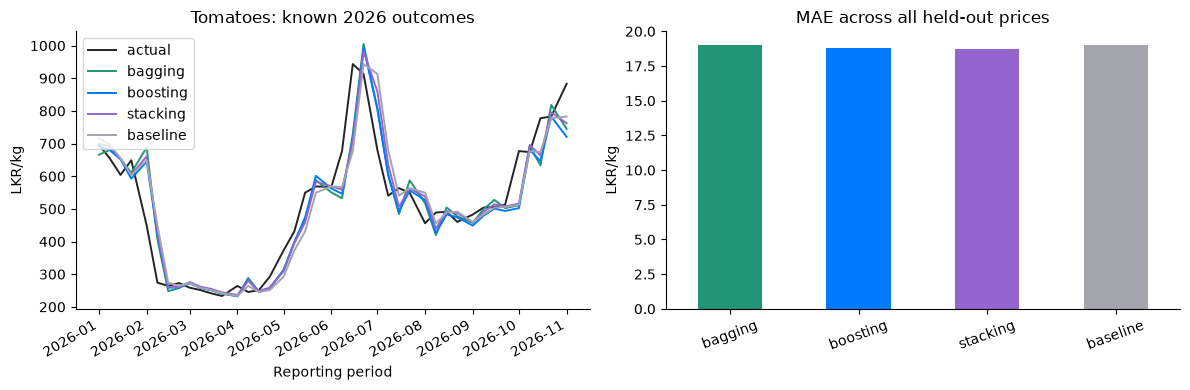

name,Previous report,Random forest,Temporal stacking,XGBoost
food,,,,
Brinjal,25.48,25.71,24.55,24.26
Cabbage,14.40,15.14,15.33,14.68
Carrots,19.69,21.02,20.47,20.22
Garlic,8.68,8.55,9.43,9.33
Green beans,47.51,44.63,43.23,46.16
Green chillies,82.93,82.59,77.54,80.70
Imported big onions,10.05,11.04,10.86,10.55
Imported potatoes,5.94,6.04,6.40,6.23
Leeks,21.23,20.74,20.48,20.60


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
example = predictions.loc[predictions.commodity == 'Tomatoes'].set_index('date')
example[['actual','bagging','boosting','stacking','baseline']].plot(ax=axes[0], color=[palette[k] for k in ['actual','bagging','boosting','stacking','baseline']], linewidth=1.4)
axes[0].set(title='Tomatoes: known 2026 outcomes', ylabel='LKR/kg', xlabel='Reporting period')
scores.mae.plot.bar(ax=axes[1], color=[palette[k] for k in scores.index])
axes[1].set(title='MAE across all held-out prices', ylabel='LKR/kg', xlabel='')
axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()
food_scores = pd.DataFrame([{'food': food, **metric} for food, group in predictions.groupby('commodity') for metric in metrics(group)])
display(food_scores.pivot(index='food', columns='name', values='mae').round(2))

## What affects the results?
The tables below show holdout permutation importance for random forest and XGBoost: how much the fractional-change MAE increases when one input column is shuffled. They are diagnostics computed **after** evaluation, not tuning inputs. Correlated lag features share information, so this is not proof of independent or causal effects. Negative values can occur.

For stacking, inspect the combiner coefficients alongside its regularization and validation periods. Coefficients are not normalized importance percentages. Shared base-model errors and changes between historical regimes can limit stacking's improvement.

Common limits: missing price histories, a short lag window, source/extraction errors, and market changes. Rainfall, exchange rates, policy and supply can matter in reality, but they are not measured inputs here; we cannot claim to estimate their effects.

Random forest


,feature,increase_in_return_mae
0,change_1,0.002592
1,commodity,0.001555
2,trend_4,0.000951
3,lag_2,0.000645
4,season_sin,0.000642
5,std_4,0.000602


XGBoost


,feature,increase_in_return_mae
0,change_1,0.001870
1,commodity,0.001445
2,season_sin,0.001039
3,mean_4,0.000379
4,std_4,0.000236
5,lag_1,0.000078


,period,commodity,actual,stacking,absolute_error
5536,2026-07-W2,Green chillies,1429.31,1117.70,311.61
5036,2026-01-W1,Green chillies,1262.22,1524.42,262.20
5556,2026-07-W3,Green chillies,1688.46,1430.11,258.35
5489,2026-06-W3,Tomatoes,943.57,707.09,236.48
5129,2026-02-W1,Tomatoes,449.20,661.01,211.81
5055,2026-01-W2,Green beans,648.93,855.95,207.02
5035,2026-01-W1,Green beans,900.40,1093.72,193.32
5516,2026-07-W1,Green chillies,1118.52,931.21,187.31


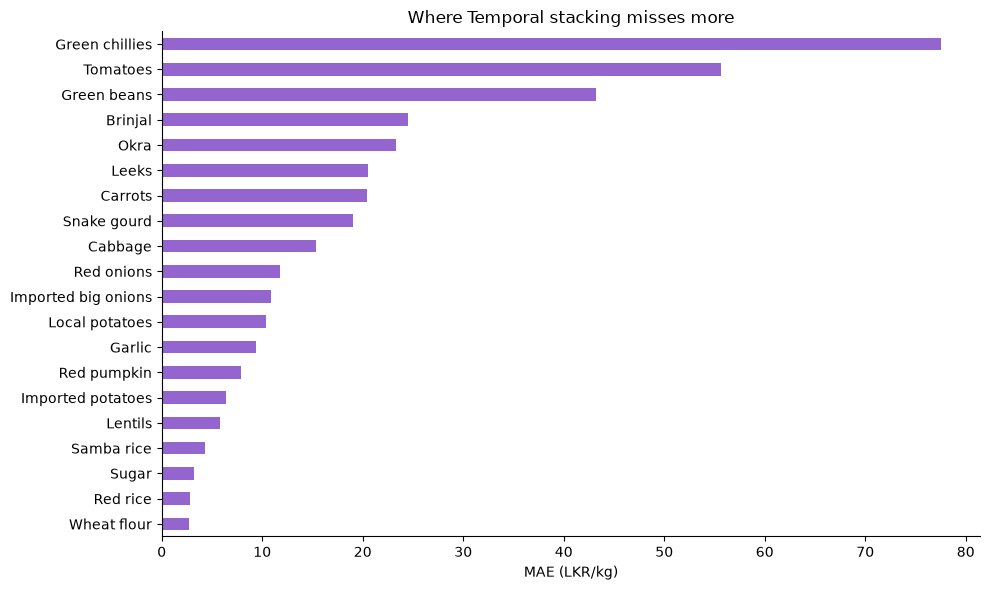

In [8]:
for method, factors in report['feature_factors'].items():
    print(LABELS[method])
    display(pd.DataFrame(factors).head(6))
errors = predictions.assign(absolute_error=(predictions[best] - predictions.actual).abs())
display(errors.nlargest(8, 'absolute_error')[['period','commodity','actual',best,'absolute_error']].round(2))
fig, ax = plt.subplots(figsize=(10, 6))
errors.groupby('commodity').absolute_error.mean().sort_values().plot.barh(ax=ax, color=palette[best])
ax.set(title=f'Where {LABELS[best]} misses more', xlabel='MAE (LKR/kg)', ylabel='')
plt.tight_layout()
plt.show()

## Future prediction example
The example below forecasts 8 reporting steps after the latest observation with a separate all-data model set. Every unknown price remains unlabeled: there is no actual price or future accuracy score yet. A future estimate cannot be presented as a tested outcome. Errors can accumulate because later steps use predicted inputs.

,date,period,step,actual,baseline,bagging,boosting,stacking
0,2026-11-08,2026-11-W2,1,None,883.2,870.398129,863.538538,879.842328
1,2026-11-15,2026-11-W3,2,None,883.2,806.726860,781.072004,851.432887
2,2026-11-22,2026-11-W4,3,None,883.2,744.010888,719.516994,814.346056
3,2026-12-01,2026-12-W1,4,None,883.2,684.804435,680.079290,779.386753
4,2026-12-08,2026-12-W2,5,None,883.2,641.875120,659.683579,744.525675
5,2026-12-15,2026-12-W3,6,None,883.2,626.652394,647.838406,717.690003
6,2026-12-22,2026-12-W4,7,None,883.2,625.278316,634.209996,696.577874
7,2027-01-01,2027-01-W1,8,None,883.2,622.040027,620.358108,686.393280


Recursive estimates from the latest available report. Earlier missing releases are also estimated; errors can grow with each step. Actual future prices and accuracy are unknown.


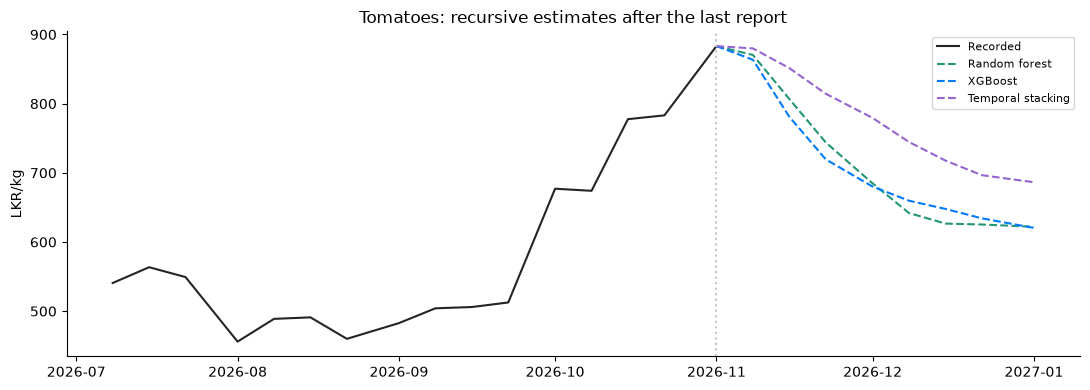

In [9]:
future_bundle = joblib.load(ARTIFACTS / 'forecast_models.joblib')
future = forecast(future_bundle, panel, 'Tomatoes', steps=8)
display(pd.DataFrame(future['rows']))
print(future['warning'])
fig, ax = plt.subplots(figsize=(11, 4))
history = pd.DataFrame(future['history'])
path = pd.DataFrame(future['rows'])
ax.plot(pd.to_datetime(history.date), history.actual, color=palette['actual'], label='Recorded')
for key in MODEL_KEYS:
    dates = pd.to_datetime([future['origin_date'], *path.date.tolist()])
    values = [future['origin_price'], *path[key].tolist()]
    ax.plot(dates, values, '--', color=palette[key], label=LABELS[key])
ax.axvline(pd.Timestamp(future['origin_date']), color='#c4c4ca', linestyle=':')
ax.set(title='Tomatoes: recursive estimates after the last report', ylabel='LKR/kg')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Checks and interpretation
The checks below verify that training ends before the holdout and that changing a target or future price cannot alter the earlier input features.

The results are descriptive comparisons from one holdout. No statistical significance claim or calibrated forecast interval is provided.

In [10]:
assert train.slot.max() < test.slot.min()
assert all(f['train_end'] < f['validation_start'] for f in report['folds'])
changed = panel.copy()
cutoff = pd.Timestamp('2026-06-01')
changed.loc[changed.date >= cutoff, 'price'] *= 7
altered = make_features(changed)
keys = ['slot','commodity']
a = rows.loc[rows.date <= cutoff].set_index(keys)[NUMERIC]
b = altered.loc[altered.date <= cutoff].set_index(keys)[NUMERIC]
pd.testing.assert_frame_equal(a, b)
assert np.isfinite(predictions[['actual', *MODEL_KEYS, 'baseline']]).all().all()
print('Date separation, past-only features and finite predictions verified.')

Date separation, past-only features and finite predictions verified.


## Conclusion
Stacking has the lowest held-out MAE (18.75 LKR/kg), about 1.3% below the previous-report baseline. Random forest has the lowest ensemble RMSE and the highest ensemble direction score; XGBoost has the lowest MAPE. The differences are small and vary by metric. Future predictions remain unverified estimates.

## Files used by the app
`backend/app/ml.py` is the shared training and inference implementation. This notebook contains the same implementation for review. `backend/app/main.py` exposes comparisons and forecasts through FastAPI; React calls those endpoints. The saved historical and future models are separate files under `backend/artifacts/`.

The application uses the original source attribution in `SOURCES.md` and the contribution acknowledgement in `AI_USAGE.md`.